# 05 · Model selection

Candidates, all evaluated with the **same 5 folds** over the 160k train+valid clients (test still untouched):

| Family | Models |
|---|---|
| meta-learners, linear | S-, T-learner, class transformation, X-learner and DR-learner (logistic outcome models, ridge effect models) |
| non-monotonic linear | the same with a cubic-spline basis on every numeric feature |
| tree-based | gradient boosting T/S/class transformation, X/DR with boosted effect models |
| causal forest | generalised random forest (econml `grf.CausalForest`), splits chosen on effect heterogeneity |
| ensembles | average percentile rank of several models |

Features: the step-2 table (notebook 04 showed more features do not help). Selection rule: the highest mean Qini
wins **only if it beats the simplest strong model by more than fold-to-fold noise**; otherwise the simpler model is
kept.

In [1]:
import sys, time
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from uplift.features import load_model_table
from uplift.metrics import cv_evaluate
from uplift.models import (BASE_SPEC, CausalForestModel, ClassTransformation, DRLearner, RankEnsemble,
                           SLearner, TLearner, XLearner, selected_model)

FIG = ROOT / "reports" / "figures"
df = load_model_table()
pool = df[df.split != "test"].reset_index(drop=True)
print(f"CV pool: {len(pool):,} clients")

CV pool: 160,031 clients


In [2]:
shallow = {"max_depth": 3, "min_samples_leaf": 1000, "max_iter": 150}
candidates = {
    # family, name: factory
    ("linear", "T-learner"): lambda: TLearner(),
    ("linear", "S-learner"): lambda: SLearner(),
    ("linear", "class transformation"): lambda: ClassTransformation(),
    ("linear", "X-learner"): lambda: XLearner(),
    ("linear", "DR-learner"): lambda: DRLearner(),
    ("splines", "T-learner"): lambda: TLearner(learner="logistic_spline", params={"C": 0.1}),
    ("splines", "class transformation"): lambda: ClassTransformation(learner="logistic_spline", params={"C": 0.1}),
    ("splines", "X-learner"): lambda: XLearner(learner="logistic_spline", params={"C": 0.1},
                                              effect_learner="ridge_spline", effect_params={"alpha": 100}),
    ("boosting", "T-learner"): lambda: TLearner(learner="boosting", params=shallow),
    ("boosting", "S-learner"): lambda: SLearner(learner="boosting", params=shallow),
    ("boosting", "class transformation"): lambda: ClassTransformation(learner="boosting", params=shallow),
    ("boosting", "X-learner"): lambda: XLearner(effect_learner="boosting_reg"),
    ("boosting", "DR-learner"): lambda: DRLearner(effect_learner="boosting_reg"),
    ("causal forest", "leaf 200"): lambda: CausalForestModel(n_estimators=200, min_samples_leaf=200),
    ("causal forest", "leaf 1000, depth 8"): lambda: CausalForestModel(n_estimators=200, min_samples_leaf=1000, max_depth=8),
    ("ensemble", "T + class transformation"): lambda: RankEnsemble([TLearner, ClassTransformation]),
    ("ensemble", "T + CT + X + DR"): lambda: RankEnsemble([TLearner, ClassTransformation, XLearner, DRLearner]),
}

folds, rows = {}, []
for key, make in candidates.items():
    t0 = time.time()
    r = cv_evaluate(pool, make)
    folds[key] = r
    rows.append((*key, r.qini.mean() * 1000, r["uplift@10%"].mean() * 100, r["uplift@30%"].mean() * 100, time.time() - t0))
res = pd.DataFrame(rows, columns=["family", "model", "Qini ×1000", "uplift@10% pp", "uplift@30% pp", "CV seconds"]).set_index(["family", "model"])

ref = folds[("linear", "T-learner")].qini.to_numpy()
t_crit = stats.t.ppf(0.975, df=4)
for key in res.index:
    d = (folds[key].qini.to_numpy() - ref) * 1000
    half = t_crit * d.std(ddof=1) / np.sqrt(len(d)) if d.std() > 0 else 0.0
    res.loc[key, "Δ Qini vs linear T (95% CI)"] = f"{d.mean():+.2f} [{d.mean() - half:+.2f}, {d.mean() + half:+.2f}]"
res.round(2)

Qini ×1000  uplift@10% pp  \
family        model                                                 
linear        T-learner                       3.39          10.40   
              S-learner                       1.39           4.73   
              class transformation            3.35           9.64   
              X-learner                       3.36           9.64   
              DR-learner                      3.35           9.47   
splines       T-learner                       2.97           9.30   
              class transformation            2.67           8.94   
              X-learner                       2.96           8.93   
boosting      T-learner                       2.33           8.63   
              S-learner                       2.93           9.34   
              class transformation            2.79           9.03   
              X-learner                       3.04           9.94   
              DR-learner                      2.82           9.16   
causal forest leaf 200                        2.41           8.56   
              leaf 1000, depth 8              1.99           6.88   
ensemble      T + class transformation        3.42           9.88   
              T + CT + X + DR                 3.40           9.58   

                                        uplift@30% pp  CV seconds  \
family        model                                                 
linear        T-learner                          6.75        4.77   
              S-learner                          4.51        4.29   
              class transformation               6.74        4.24   
              X-learner                          6.82       11.09   
              DR-learner                         6.80       13.03   
splines       T-learner                          6.66       14.05   
              class transformation               6.32       11.43   
              X-learner                          6.71       19.48   
boosting      T-learner                          5.95       11.47   
              S-learner                          6.48       13.08   
              class transformation               6.51        7.39   
              X-learner                          6.63       19.82   
              DR-learner                         6.18       14.89   
causal forest leaf 200                           5.73      171.78   
              leaf 1000, depth 8                 4.93      108.79   
ensemble      T + class transformation           6.77        8.73   
              T + CT + X + DR                    6.96       22.49   

                                       Δ Qini vs linear T (95% CI)  
family        model                                                 
linear        T-learner                       +0.00 [+0.00, +0.00]  
              S-learner                       -2.00 [-2.99, -1.01]  
              class transformation            -0.04 [-0.10, +0.01]  
              X-learner                       -0.03 [-0.08, +0.02]  
              DR-learner                      -0.04 [-0.08, +0.00]  
splines       T-learner                       -0.42 [-1.19, +0.34]  
              class transformation            -0.72 [-1.30, -0.13]  
              X-learner                       -0.43 [-0.89, +0.03]  
boosting      T-learner                       -1.06 [-2.09, -0.04]  
              S-learner                       -0.46 [-1.13, +0.21]  
              class transformation            -0.60 [-1.60, +0.40]  
              X-learner                       -0.35 [-1.28, +0.59]  
              DR-learner                      -0.57 [-1.38, +0.25]  
causal forest leaf 200                        -0.98 [-1.89, -0.06]  
              leaf 1000, depth 8              -1.40 [-2.49, -0.31]  
ensemble      T + class transformation        +0.03 [-0.02, +0.08]  
              T + CT + X + DR                 +0.01 [-0.02, +0.03]

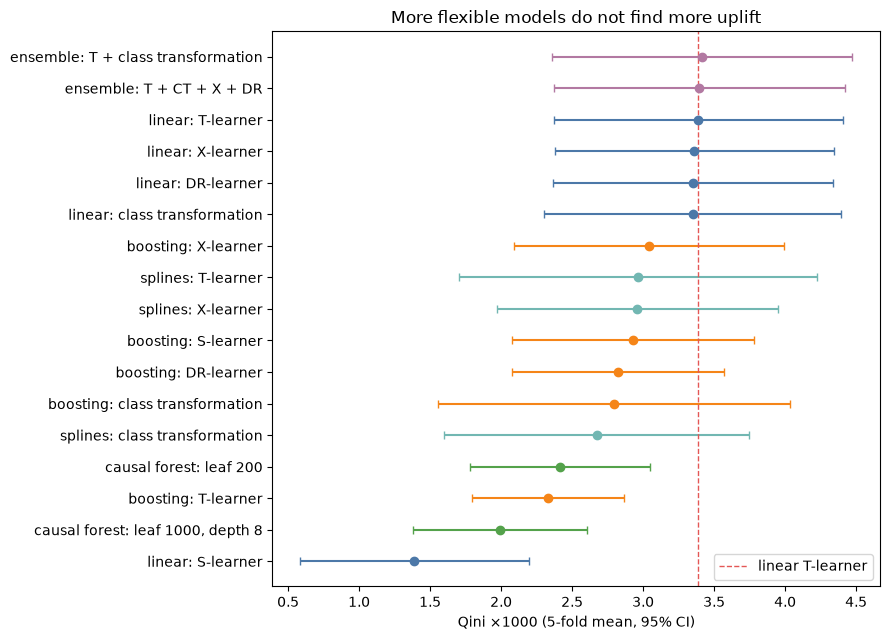

In [3]:
order = res.sort_values("Qini ×1000").index
colors = {"linear": "#4C78A8", "splines": "#72B7B2", "boosting": "#F58518", "causal forest": "#54A24B", "ensemble": "#B279A2"}
fig, ax = plt.subplots(figsize=(9, 6.5))
for i, key in enumerate(order):
    q = folds[key].qini.to_numpy() * 1000
    half = t_crit * q.std(ddof=1) / np.sqrt(len(q))
    ax.errorbar(q.mean(), i, xerr=half, fmt="o", color=colors[key[0]], capsize=3)
ax.axvline(ref.mean() * 1000, color="#E45756", ls="--", lw=1, label="linear T-learner")
ax.set_yticks(range(len(order)), [f"{f}: {m}" for f, m in order])
ax.set_xlabel("Qini ×1000 (5-fold mean, 95% CI)")
ax.set_title("More flexible models do not find more uplift")
ax.legend(loc="lower right"); fig.tight_layout(); fig.savefig(FIG / "05_model_selection.png", dpi=150); plt.show()

## What the selected model has learned

The logistic T-learner is two logistic regressions on standardised features. The difference between the
treated-arm and control-arm coefficients is how each feature shifts the SMS effect (in log-odds), which can be
read directly by a marketing team:

In [4]:
final = selected_model().fit(pool, pool.treatment_flg, pool.target)
names = final.m1_.named_steps["prep"].get_feature_names_out()
coef = pd.DataFrame({
    "treated arm": final.m1_.named_steps["clf"].coef_[0],
    "control arm": final.m0_.named_steps["clf"].coef_[0],
}, index=[n.split("__", 1)[1] for n in names])
coef["effect shift (treated − control)"] = coef["treated arm"] - coef["control arm"]
coef.reindex(coef["effect shift (treated − control)"].abs().sort_values(ascending=False).index).head(10).round(3)

,treated arm,control arm,effect shift (treated − control)
total_spend,-0.898,-0.600,-0.299
n_transactions,1.735,1.618,0.117
card_age_days,-0.086,-0.004,-0.083
points_received,0.110,0.033,0.077
redeemed_before_campaign,0.220,0.146,0.074
age,0.128,0.058,0.070
gender_F,0.168,0.110,0.058
avg_basket,0.412,0.358,0.055
points_spent,0.004,-0.035,0.038
days_since_first_redeem,0.109,0.071,0.037


How to read this table:
* `total_spend` (−0.29) and `n_transactions` (+0.11) are strongly collinear and must be read together: at the same
  number of visits, **lower spend (smaller baskets) means a larger SMS effect**, the same pattern notebook 04 found.
* Older clients, women, and clients who already redeem points react more; newer cards react more than old ones.
* `redeem_before_issue` is a data-error flag shared by only ~400 training clients, so its large coefficient is noise.
  It stays in the model as a harmless indicator but should not be interpreted.

## Decision

* **Selected: logistic T-learner on the step-2 table** (`uplift.models.selected_model`).
* No family beats it beyond noise. Ensembles land within ±0.05 of it and X-/DR-learners with linear effect models
  tie. Splines, gradient boosting and causal forests all score lower (−0.4 to −1.4 Qini ×1000); the difference is
  significant for the boosted T-learner, the spline class transformation and both causal forests.
* Why the simple model wins here: the average effect is +3.3 pp on a 60% base rate, so the individual effect is a
  small difference between two noisy probabilities. Flexible learners spend their capacity on the much larger
  purchase signal and on noise; a regularised linear model with a few well-built features is more stable.
* The selected model also wins on everything that matters after deployment: fits in seconds, scores in
  microseconds, and every coefficient can be explained.
* Step 6 refits it on train+valid and evaluates it **once** on the untouched test split.